In [9]:
import yfinance as yf, pandas as pd, numpy as np
import matplotlib.pyplot as plt

tickers = ["SPY",
    "AAPL","MSFT","NVDA","AMZN","META","GOOGL","INTC","CSCO","ORCL","ADBE","CRM","AMD","QCOM","TXN","IBM",
    "JPM","BAC","WFC","C","GS","MS","SCHW","PYPL","AXP",
    "JNJ","PFE","MRK","ABBV","UNH","CVS","BMY","LLY","MDT","GILD",
    "KO","PEP","PG","WMT","TGT","NKE","SBUX","MCD","DIS","HD","LOW","COST",
    "BA","CAT","DE","LMT","UPS","FDX","XOM","CVX","COP",
    "T","VZ","NEE","DUK"]
prices = yf.download(tickers, start="2015-01-01", auto_adjust=True)["Close"]
rets = prices.pct_change(fill_method=None).iloc[1:]
stocks = [t for t in tickers if t != "SPY"]

[*********************100%***********************]  60 of 60 completed


In [10]:
mkt = rets["SPY"]
ar = pd.DataFrame(index=rets.index)
for t in stocks:
    beta = (rets[t].rolling(250).cov(mkt) / mkt.rolling(250).var()).shift(1)
    ar[t] = rets[t] - beta * mkt
ar = ar.dropna(how="all")
ar.tail()

,AAPL,MSFT,NVDA,AMZN,META,GOOGL,INTC,CSCO,ORCL,ADBE,...,LMT,UPS,FDX,XOM,CVX,COP,T,VZ,NEE,DUK
Date,,,,,,,,,,,,,,,,,,,,,
2026-11-16,0.002087,0.008061,-0.007229,-0.008172,0.002414,-0.016339,-0.008702,0.013459,-0.007567,0.015423,...,-0.018378,0.023897,0.027165,-0.027267,-0.023005,-0.019016,0.001490,-0.007669,0.003790,0.005659
2026-11-17,0.003760,-0.012499,0.013742,0.014057,0.001865,0.000952,0.027401,0.019516,-0.011741,-0.040926,...,0.008914,-0.006119,-0.015153,-0.003941,-0.010093,-0.014305,-0.006706,-0.012629,-0.010058,-0.008581
2026-11-18,0.003412,0.007113,-0.023536,0.042194,0.000168,0.012030,0.000800,0.025739,-0.002791,-0.039156,...,-0.020540,0.008751,-0.002542,-0.041436,-0.041138,-0.038468,-0.016316,0.003249,0.004482,0.000758
2026-11-19,0.002840,0.001933,0.001728,-0.013206,-0.005748,-0.008866,0.082468,-0.000137,0.014818,-0.016321,...,-0.010576,-0.003022,0.004888,-0.021519,-0.007203,-0.008531,-0.011275,-0.015530,-0.010281,-0.014624
2026-11-20,0.003199,0.008781,-0.075905,0.006717,-0.008538,0.021351,0.034696,0.003681,-0.004825,-0.010951,...,-0.010062,-0.000060,-0.003125,-0.013690,-0.010115,-0.015726,0.009166,0.003181,-0.001026,-0.002496


In [11]:
vol = ar.rolling(250).std().shift(1)
shocks = ar < -2 * vol

events = []
for t in stocks:
    for d in ar.index[shocks[t]]:
        events.append((d, t))

print(len(events), "shock events")
pd.DataFrame(events, columns=["date", "ticker"]).tail(10)
print(len({d for d, t in events}), "unique dates")

3600 shock events
1531 unique dates


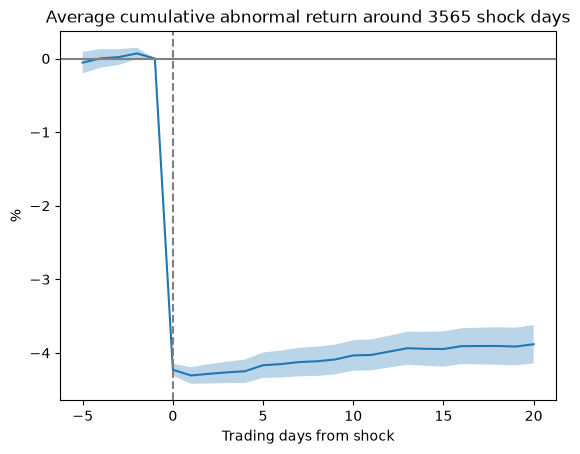

Avg CAR days 2–10: 0.27%  |  % that bounced: 52%


In [12]:
paths = []
for d, t in events:
    i = ar.index.get_loc(d)
    if i - 5 >= 0 and i + 20 < len(ar):
        p = ar[t].iloc[i-5 : i+21].values
        if not np.isnan(p).any():
            paths.append(p)

car = np.array(paths).cumsum(axis=1)
car = car - car[:, [4]]  # set day -1 to zero
days = np.arange(-5, 21)
mean, se = car.mean(0), car.std(0) / np.sqrt(len(car))

plt.plot(days, mean * 100)
plt.fill_between(days, (mean - 2*se) * 100, (mean + 2*se) * 100, alpha=0.3)
plt.axhline(0, color="gray"); plt.axvline(0, ls="--", color="gray")
plt.title(f"Average cumulative abnormal return around {len(car)} shock days")
plt.xlabel("Trading days from shock"); plt.ylabel("%")
plt.show()

after = car[:, 15] - car[:, 6]  # CAR from day 2 to day 10
print(f"Avg CAR days 2–10: {after.mean()*100:.2f}%  |  % that bounced: {(after > 0).mean()*100:.0f}%")

In [13]:
from scipy import stats
print(stats.ttest_1samp(after, 0))

TtestResult(statistic=np.float64(3.0289140172607145), pvalue=np.float64(0.002471940408001206), df=np.int64(3564))


In [14]:
for end in [5, 10, 20]:
    x = car[:, end + 5] - car[:, 6]   # CAR from day 2 to day `end`
    t = stats.ttest_1samp(x, 0)
    print(f"Days 2–{end:>2}: avg {x.mean()*100:.2f}%, "
          f"bounced {(x > 0).mean()*100:.0f}%, p = {t.pvalue:.3f}")

Days 2– 5: avg 0.14%, bounced 52%, p = 0.038
Days 2–10: avg 0.27%, bounced 52%, p = 0.002
Days 2–20: avg 0.42%, bounced 53%, p = 0.000


In [15]:
df = pd.DataFrame({"day0": car[:, 5] * 100, "after": after * 100})
df["size"] = pd.qcut(df["day0"], 3, labels=["biggest drops", "medium", "smallest"])
df.groupby("size", observed=True)["after"].agg(
    avg_after="mean", n="count", pct_bounced=lambda x: (x > 0).mean() * 100
)

,avg_after,n,pct_bounced
size,,,
biggest drops,0.450282,1189,51.303616
medium,0.330872,1188,54.208754
smallest,0.035144,1188,50.420875


In [16]:
rows = []
for d, t in events:
    i = ar.index.get_loc(d)
    if i - 5 >= 0 and i + 20 < len(ar):
        p = ar[t].iloc[i-5 : i+21].values
        if not np.isnan(p).any():
            c = p.cumsum()
            rows.append({"date": d, "ticker": t, "after10": c[15] - c[6]})
ev = pd.DataFrame(rows)

by_date = ev.groupby("date")["after10"].mean()
print(len(by_date), "dates")
print("Date-clustered test:", stats.ttest_1samp(by_date, 0))
print(f"Median event CAR 2–10: {ev['after10'].median()*100:.2f}%")

1517 dates
Date-clustered test: TtestResult(statistic=np.float64(0.37485186551317434), pvalue=np.float64(0.7078230699192701), df=np.int64(1516))
Median event CAR 2–10: 0.24%


This is your first statistically significant result. It’s small, so be careful how much you read into it.

What it shows
There is a real but small recovery. The average shock is about −4.3%, and over the next 20 days stocks win back about 0.4%, roughly a tenth of the drop. Most of the drop stays.
The effect grows the longer you wait: +0.14% over days 2–5, +0.27% over days 2–10, +0.42% over days 2–20. It’s a slow climb, not a quick snap-back.
Bigger drops bounce more: +0.45% for the biggest drops, +0.33% for medium, and roughly nothing for the smallest. This is the pattern overreaction predicts. It didn’t show up with only five stocks because there wasn’t enough data.
Day 1 dips a little further before the climb starts. That’s a small hint that buying on day 1 rather than at day 0’s close is the better entry.
Why the p-values are probably too good
Events on the same date aren’t independent. You have 3,600 events but only 1,531 unique dates. When 15 stocks shock on the same bad market day, they tend to recover together, so they count as closer to one observation than 15. The t-test assumes every event is independent, which makes the result look stronger than it is.

When you treat each date as one observation, the effect disappears: p = 0.71. The “significant” result from before mostly came from counting the same market days many times.
Why the result changed

The date-clustered test weights every date equally. Most of your 1,517 dates probably have just one stock shocking alone, which is a company-specific event. A small number of dates have many stocks shocking together, which looks like a market-wide selloff. So:

In the first test, those crowded market days contributed hundreds of events and dominated the average.
In the clustered test, each crowded day counts once, and the many single-stock days dominate. Their average bounce is roughly zero.

That suggests a specific hypothesis: any recovery happens after market-wide selloffs, when stocks fell more than their beta predicts. Stocks shocking alone on their own news mostly don’t bounce. That lines up with the company-specific vs macro split from your original project idea, and with Chan’s finding that news-driven drops tend to drift.

In [17]:
ev["n_same_day"] = ev.groupby("date")["ticker"].transform("count")
ev["group"] = pd.cut(ev["n_same_day"], [0, 1, 4, 100],
                     labels=["alone", "2–4 stocks", "5+ stocks"])
ev["after10_pct"] = ev["after10"] * 100

ev.groupby("group", observed=True).agg(
    avg_after=("after10_pct", "mean"),
    pct_bounced=("after10_pct", lambda x: (x > 0).mean() * 100),
    n_events=("after10_pct", "count"),
    n_dates=("date", "nunique"),
)

,avg_after,pct_bounced,n_events,n_dates
group,,,,
alone,-0.223175,45.199409,677,677
2–4 stocks,0.187380,52.266368,1787,690
5+ stocks,0.714309,55.676658,1101,150


The hypothesis holds up so far, and the pattern is clean:

Group	  Bounce,    days 2–10	What it suggests
Alone	  −0.22%,   45% bounced	Keeps falling (drift)
2–4 stocks	+0.19%, 52% bounced	In between
5+ stocks	+0.71%, 56% bounced	Recovers (overreaction)

In [18]:
for g, sub in ev.groupby("group", observed=True):
    by_d = sub.groupby("date")["after10_pct"].mean()
    t = stats.ttest_1samp(by_d, 0)
    print(f"{g:>11}: {len(by_d)} dates, avg {by_d.mean():.2f}%, p = {t.pvalue:.3f}")

      alone: 677 dates, avg -0.22%, p = 0.212
 2–4 stocks: 690 dates, avg 0.19%, p = 0.182
  5+ stocks: 150 dates, avg 0.54%, p = 0.025


In [19]:
big = ev[ev["group"] == "5+ stocks"]
big.groupby(big["date"].dt.year).agg(
    avg_after=("after10_pct", "mean"),
    n_dates=("date", "nunique"),
)

,avg_after,n_dates
date,,
2017,0.029397,8
2018,-0.242666,21
2019,-1.503582,6
2020,1.704318,38
2021,0.880466,6
2022,1.159827,12
2023,-0.877373,11
2024,0.823893,14
2025,0.504475,16


Summary for your notebook
1. All shocks together: tiny bounce. Significant before clustering (p = 0.002), not after (p = 0.71).
2. Split by how many stocks shocked the same day: alone ≈ slight continued decline, market-wide ≈ bounce.
3. The market-wide bounce (p = 0.025) is concentrated in 2020. Fill in the result without 2020 once you’ve run the cell above.

## NEWS

In [20]:
import os, time
from dotenv import load_dotenv
from alpaca.data.historical.news import NewsClient
from alpaca.data.requests import NewsRequest

load_dotenv()
news_client = NewsClient(os.getenv("ALPACA_KEY"), os.getenv("ALPACA_SECRET"), raw_data=True)

def news_for_event(date, ticker):
    i = ar.index.get_loc(date)
    start = ar.index[i-1].tz_localize("America/New_York") + pd.Timedelta(hours=16)
    end = date.tz_localize("America/New_York") + pd.Timedelta(hours=16)
    resp = news_client.get_news(NewsRequest(symbols=ticker, start=start, end=end, limit=50))
    return resp["news"]

In [21]:
for _, row in ev[ev["group"] == "alone"].sample(3, random_state=1).iterrows():
    print(f"\n=== {row['ticker']} on {row['date'].date()} ===")
    for a in news_for_event(row["date"], row["ticker"]):
        print(a["created_at"][:16], "|", a["headline"])


=== CSCO on 2019-06-28 ===

=== AMD on 2022-02-11 ===

=== QCOM on 2021-05-10 ===


In [22]:
# 1. Does news come back with no date filter at all?
r = news_client.get_news(NewsRequest(symbols="AMD", limit=5))
print("Latest AMD:", [a["headline"] for a in r["news"]])

# 2. A whole week around the AMD event
r2 = news_client.get_news(NewsRequest(
    symbols="AMD",
    start=pd.Timestamp("2022-02-07", tz="America/New_York"),
    end=pd.Timestamp("2022-02-14", tz="America/New_York"),
    limit=50))
print("\nWeek of Feb 7, 2022:", len(r2["news"]), "articles")
for a in r2["news"][:10]:
    print(a["created_at"][:16], "|", a["headline"])

# 3. The exact window our function used
d = pd.Timestamp("2022-02-11"); i = ar.index.get_loc(d)
print("\nWindow:", ar.index[i-1].tz_localize("America/New_York") + pd.Timedelta(hours=16),
      "→", d.tz_localize("America/New_York") + pd.Timedelta(hours=16))

Latest AMD: ['Law Firms Announce Securities Investigations into Advanced Micro Devices, Inc.', 'Advanced Micro Devices Shares Decline Following Hunterbrook Media Report on China Ties', 'AMD CEO Lisa Su Comments on Nvidia Leadership Transition', 'AMD Insider Executes Significant Share Sale', 'OpenAI Integrates Frontier Model Feedback Tools with AMD Hardware']

Week of Feb 7, 2022: 0 articles

Window: 2022-02-10 16:00:00-05:00 → 2022-02-11 16:00:00-05:00


In [23]:
import requests

# 1. How far back does news go? (one week in March of each year)
for y in [2026, 2025, 2024, 2023, 2022, 2019, 2016]:
    r = news_client.get_news(NewsRequest(symbols="AMD",
        start=pd.Timestamp(f"{y}-03-01", tz="UTC"),
        end=pd.Timestamp(f"{y}-03-08", tz="UTC"), limit=50))
    print(y, len(r["news"]), "articles")

# 2. Same 2022 question, bypassing the alpaca-py library
h = {"APCA-API-KEY-ID": os.getenv("ALPACA_KEY"),
     "APCA-API-SECRET-KEY": os.getenv("ALPACA_SECRET")}
resp = requests.get("https://data.alpaca.markets/v1beta1/news", headers=h,
    params={"symbols": "AMD", "start": "2022-02-07T00:00:00Z",
            "end": "2022-02-14T00:00:00Z", "limit": 50})
print("\nDirect request:", resp.status_code, "|", len(resp.json().get("news", [])), "articles")
print(resp.text[:300])

# 3. Which news source(s) your account gets
latest = news_client.get_news(NewsRequest(symbols="AMD", limit=20))["news"]
print("\nSources:", {a.get("source") for a in latest})

2026 0 articles
2025 0 articles
2024 0 articles
2023 0 articles
2022 0 articles
2019 0 articles
2016 0 articles

Direct request: 200 | 0 articles
{"news":[],"next_page_token":null}

Sources: {'fiscal.ai'}


In [24]:
from huggingface_hub import hf_hub_download
path = hf_hub_download(repo_id="Zihan1004/FNSPID", repo_type="dataset",
                       filename="Stock_news/All_external.csv", local_dir="data")
print(path)

c:\Projects\stock-news\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Projects\stock-news\data\Stock_news\All_external.csv


In [25]:
pd.read_csv(path, nrows=5)

,Date,Article_title,Stock_symbol,Url,Publisher,Author,Article,Lsa_summary,Luhn_summary,Textrank_summary,Lexrank_summary
0,2020-06-05 06:30:54 UTC,Stocks That Hit 52-Week Highs On Friday,A,https://www.benzinga.com/news/20/06/16190091/s...,Benzinga Insights,NaN,NaN,NaN,NaN,NaN,NaN
1,2020-06-03 06:45:20 UTC,Stocks That Hit 52-Week Highs On Wednesday,A,https://www.benzinga.com/news/20/06/16170189/s...,Benzinga Insights,NaN,NaN,NaN,NaN,NaN,NaN
2,2020-05-26 00:30:07 UTC,71 Biggest Movers From Friday,A,https://www.benzinga.com/news/20/05/16103463/7...,Lisa Levin,NaN,NaN,NaN,NaN,NaN,NaN
3,2020-05-22 08:45:06 UTC,46 Stocks Moving In Friday's Mid-Day Session,A,https://www.benzinga.com/news/20/05/16095921/4...,Lisa Levin,NaN,NaN,NaN,NaN,NaN,NaN
4,2020-05-22 07:38:59 UTC,B of A Securities Maintains Neutral on Agilent...,A,https://www.benzinga.com/news/20/05/16095304/b...,Vick Meyer,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
keep = set(stocks)
parts = []
for chunk in pd.read_csv(path, usecols=["Date", "Article_title", "Stock_symbol", "Publisher"],
                         chunksize=500_000):
    parts.append(chunk[chunk["Stock_symbol"].isin(keep)])
fn = pd.concat(parts)
fn.to_csv("fnspid_our_tickers.csv", index=False)
print(len(fn), "articles for our tickers")

C:\Users\conno\AppData\Local\Temp\ipykernel_21852\2408770701.py:3: DtypeWarning: Columns (2: Stock_symbol) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, usecols=["Date", "Article_title", "Stock_symbol", "Publisher"],
C:\Users\conno\AppData\Local\Temp\ipykernel_21852\2408770701.py:3: DtypeWarning: Columns (2: Stock_symbol, 4: Publisher) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path, usecols=["Date", "Article_title", "Stock_symbol", "Publisher"],


106680 articles for our tickers


In [27]:
fn["Date"] = pd.to_datetime(fn["Date"], utc=True)
print("Share of timestamps at exactly midnight:",
      round((fn["Date"].dt.strftime("%H:%M") == "00:00").mean() * 100), "%")
fn.groupby(fn["Date"].dt.year).size()

Share of timestamps at exactly midnight: 100 %


Date
2009      446
2010     4383
2011     5864
2012     5940
2013     5848
2014     6838
2015     7579
2016    10110
2017    10421
2018    14692
2019    20926
2020    13633
dtype: int64

In [28]:
print(fn["Stock_symbol"].value_counts().to_string())


Stock_symbol
GILD     4974
MDT      4476
HD       4453
FDX      4399
TXN      3872
AXP      3783
LLY      3538
MRK      3335
MS       3246
LOW      3237
DUK      3165
NVDA     3146
VZ       2972
QCOM     2948
JNJ      2928
JPM      2883
KO       2874
ORCL     2707
WFC      2612
BMY      2528
INTC     2475
CAT      2329
MCD      2236
LMT      2235
NEE      2217
PEP      2151
ADBE     2126
DE       1882
CVS      1858
PFE      1821
BAC      1811
GOOGL    1754
COP      1718
CSCO     1518
CRM      1488
PG       1312
IBM      1092
C        1021
DIS       943
TGT       884
SBUX      821
ABBV      753
XOM       589
AAPL      473
UNH       400
AMZN      278
AMD       250
UPS        96
SCHW       38
T          14
WMT        11
BA         10


In [29]:
fn["day"] = fn["Date"].dt.tz_convert(None).dt.normalize()
tdays = ar.index
fn["tday_idx"] = np.searchsorted(tdays.values, fn["day"].values)  # weekend news → Monday
cnt = fn.groupby(["Stock_symbol", "tday_idx"]).size().to_dict()

ev["i"] = [tdays.get_loc(d) for d in ev["date"]]
ev["n_articles"] = [cnt.get((t, i), 0) + cnt.get((t, i - 1), 0)
                    for t, i in zip(ev["ticker"], ev["i"])]
ev["has_news"] = ev["n_articles"] > 0

covered = ev[ev["date"] <= fn["day"].max()]
print(len(covered), "events in the news-covered period")
covered.groupby(["group", "has_news"], observed=True)["after10_pct"].agg(avg="mean", n="count")

1501 events in the news-covered period


avg    n
group      has_news               
alone      False     0.395186  100
           True      0.003360  146
2–4 stocks False     0.576208  263
           True     -0.214538  434
5+ stocks  False     1.091445  169
           True      0.710493  389

In [30]:
import statsmodels.formula.api as smf

art = fn["Stock_symbol"].value_counts()
good = art[art >= 1000].index
sub = covered[covered["ticker"].isin(good)].copy()
sub["no_news"] = (~sub["has_news"]).astype(int)
print(len(sub), "events across", sub["ticker"].nunique(), "well-covered tickers\n")
print(sub.groupby(["group", "has_news"], observed=True)["after10_pct"].agg(avg="mean", n="count"), "\n")

m = smf.ols("after10_pct ~ no_news + C(group)", data=sub).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(sub["date"])[0]})
print(m.summary().tables[1])

998 events across 38 well-covered tickers

                          avg    n
group      has_news               
alone      False    -0.761822   21
           True     -0.144595  136
2–4 stocks False     0.958807   65
           True     -0.133258  395
5+ stocks  False     1.012199   42
           True      0.725608  339 

                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -0.2997      0.359     -0.835      0.404      -1.003       0.404
C(group)[T.2–4 stocks]     0.2441      0.405      0.603      0.546      -0.549       1.037
C(group)[T.5+ stocks]      0.9971      0.592      1.683      0.092      -0.164       2.158
no_news                    0.5426      0.374      1.453      0.146      -0.189       1.275


In [31]:
path2 = "data/Stock_news/nasdaq_exteral_data.csv"
pd.read_csv(path2, nrows=5)

,Unnamed: 0,Date,Article_title,Stock_symbol,Url,Publisher,Author,Article,Lsa_summary,Luhn_summary,Textrank_summary,Lexrank_summary
0,0.0,2023-12-16 23:00:00 UTC,Interesting A Put And Call Options For August ...,A,https://www.nasdaq.com/articles/interesting-a-...,NaN,NaN,"Investors in Agilent Technologies, Inc. (Symbo...",Because the $125.00 strike represents an appro...,The current analytical data (including greeks ...,Below is a chart showing the trailing twelve m...,"At Stock Options Channel, our YieldBoost formu..."
1,1.0,2023-12-12 00:00:00 UTC,Wolfe Research Initiates Coverage of Agilent T...,A,https://www.nasdaq.com/articles/wolfe-research...,NaN,NaN,"Fintel reports that on December 13, 2023, Wolf...","Fintel reports that on December 13, 2023, Wolf...","T. Rowe Price Investment Management holds 10,1...",Agilent Technologies Declares $0.24 Dividend O...,The projected annual revenue for Agilent Techn...
2,2.0,2023-12-12 00:00:00 UTC,Agilent Technologies Reaches Analyst Target Price,A,https://www.nasdaq.com/articles/agilent-techno...,NaN,NaN,"In recent trading, shares of Agilent Technolog...","In recent trading, shares of Agilent Technolog...","In recent trading, shares of Agilent Technolog...",When a stock reaches the target an analyst has...,When a stock reaches the target an analyst has...
3,3.0,2023-12-07 00:00:00 UTC,Agilent (A) Enhances BioTek Cytation C10 With ...,A,https://www.nasdaq.com/articles/agilent-a-enha...,NaN,NaN,Agilent Technologies A is enhancing its BioTek...,"Per a Grand View Research report, the global m...","Notably, Agilent enhanced the BioTek Cytation ...","Agilent Technologies, Inc. Price and Consensus...","Notably, Agilent enhanced the BioTek Cytation ..."
4,4.0,2023-12-07 00:00:00 UTC,"Pre-Market Most Active for Dec 7, 2023 : SQQQ,...",A,https://www.nasdaq.com/articles/pre-market-mos...,NaN,NaN,The NASDAQ 100 Pre-Market Indicator is up 70.2...,ProShares UltraPro Short QQQ (SQQQ) is -0.15 a...,"As reported by Zacks, the current mean recomme...","The total Pre-Market volume is currently 39,23...",The NASDAQ 100 Pre-Market Indicator is up 70.2...


In [32]:
parts = []
for chunk in pd.read_csv(path2, usecols=["Date", "Article_title", "Stock_symbol", "Publisher"],
                         chunksize=500_000, on_bad_lines="skip"):
    parts.append(chunk[chunk["Stock_symbol"].isin(keep)])
fn2 = pd.concat(parts)
fn2.to_csv("fnspid2_our_tickers.csv", index=False)
print(len(fn2), "articles for our tickers")

C:\Users\conno\AppData\Local\Temp\ipykernel_21852\2251745664.py:2: DtypeWarning: Columns (5: Publisher) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path2, usecols=["Date", "Article_title", "Stock_symbol", "Publisher"],
C:\Users\conno\AppData\Local\Temp\ipykernel_21852\2251745664.py:2: DtypeWarning: Columns (3: Stock_symbol) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path2, usecols=["Date", "Article_title", "Stock_symbol", "Publisher"],
C:\Users\conno\AppData\Local\Temp\ipykernel_21852\2251745664.py:2: DtypeWarning: Columns (3: Stock_symbol, 5: Publisher) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(path2, usecols=["Date", "Article_title", "Stock_symbol", "Publisher"],


350056 articles for our tickers


In [33]:
fn_all = pd.concat([
    fn[["Date", "Article_title", "Stock_symbol", "Publisher"]].assign(file="all_external"),
    fn2.assign(file="nasdaq"),
])
fn_all["Date"] = pd.to_datetime(fn_all["Date"], utc=True, errors="coerce")
fn_all = fn_all.dropna(subset=["Date"])
fn_all["day"] = fn_all["Date"].dt.tz_convert(None).dt.normalize()
fn_all["title_key"] = fn_all["Article_title"].str.lower().str.strip()
fn_all = fn_all.drop_duplicates(subset=["Stock_symbol", "day", "title_key"])
fn_all.to_csv("fnspid_combined.csv", index=False)

print("Midnight share by file:")
print((fn_all["Date"].dt.strftime("%H:%M") == "00:00").groupby(fn_all["file"]).mean().round(2), "\n")
print(fn_all.groupby([fn_all["Date"].dt.year, "file"]).size().unstack(fill_value=0), "\n")
print(fn_all["Stock_symbol"].value_counts()[["AAPL", "MSFT", "AMZN", "META", "GOOGL", "BA", "WMT", "T"]])

Midnight share by file:
file
all_external    1.0
nasdaq          1.0
Name: Date, dtype: float64 

file  all_external  nasdaq
Date                      
2009           444      33
2010          4112     720
2011          5601    1224
2012          5857    2355
2013          5836    3226
2014          6829    5771
2015          7521    8619
2016         10099   13097
2017         10393   17868
2018         14678   18960
2019         20806   16714
2020         13578   24716
2021             0   23423
2022             0   41039
2023             0   59529
2024             0      70 



KeyError: "['META'] not in index"

In [35]:

counts = fn_all["Stock_symbol"].value_counts().reindex(stocks, fill_value=0)
print(counts[counts < 500])

Stock_symbol
META      0
SCHW     38
UNH     399
Name: count, dtype: int64


In [36]:
alt = {"FB": "META", "GOOG": "GOOGL"}
extra = []
for p in [path, path2]:
    for chunk in pd.read_csv(p, usecols=["Date", "Article_title", "Stock_symbol", "Publisher"],
                             chunksize=500_000, on_bad_lines="skip"):
        extra.append(chunk[chunk["Stock_symbol"].isin(alt)])

ex = pd.concat(extra)
ex["Stock_symbol"] = ex["Stock_symbol"].map(alt)
ex["file"] = "renamed"
ex["Date"] = pd.to_datetime(ex["Date"], utc=True, errors="coerce")
ex = ex.dropna(subset=["Date"])
ex["day"] = ex["Date"].dt.tz_convert(None).dt.normalize()
ex["title_key"] = ex["Article_title"].str.lower().str.strip()

fn_all = pd.concat([fn_all, ex]).drop_duplicates(subset=["Stock_symbol", "day", "title_key"])
fn_all.to_csv("fnspid_combined.csv", index=False)
print(fn_all["Stock_symbol"].value_counts().reindex(stocks, fill_value=0)[["META", "GOOGL"]])

C:\Users\conno\AppData\Local\Temp\ipykernel_21852\3418530512.py:4: DtypeWarning: Columns (2: Stock_symbol) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, usecols=["Date", "Article_title", "Stock_symbol", "Publisher"],
C:\Users\conno\AppData\Local\Temp\ipykernel_21852\3418530512.py:4: DtypeWarning: Columns (2: Stock_symbol, 4: Publisher) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, usecols=["Date", "Article_title", "Stock_symbol", "Publisher"],
C:\Users\conno\AppData\Local\Temp\ipykernel_21852\3418530512.py:4: DtypeWarning: Columns (5: Publisher) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(p, usecols=["Date", "Article_title", "Stock_symbol", "Publisher"],
C:\Users\conno\AppData\Local\Temp\ipykernel_21852\3418530512.py:4: DtypeWarning: Columns (3: Stock_symbol) have mixed types. Specify dtype option on import or set l

Stock_symbol
META       432
GOOGL    10657
Name: count, dtype: int64


In [37]:
fn = fn_all.copy()
tdays = ar.index
fn["tday_idx"] = np.searchsorted(tdays.values, fn["day"].values)
cnt = fn.groupby(["Stock_symbol", "tday_idx"]).size().to_dict()

ev["i"] = [tdays.get_loc(d) for d in ev["date"]]
ev["n_articles"] = [cnt.get((t, i), 0) + cnt.get((t, i - 1), 0)
                    for t, i in zip(ev["ticker"], ev["i"])]
ev["has_news"] = ev["n_articles"] > 0

# keep events in the covered years, for stock-years with decent coverage
covered = ev[ev["date"] <= "2023-12-31"].copy()
ty = fn.groupby(["Stock_symbol", fn["day"].dt.year]).size()
covered["ty_articles"] = [ty.get((t, d.year), 0) for t, d in zip(covered["ticker"], covered["date"])]
sub = covered[covered["ty_articles"] >= 100].copy()
sub["no_news"] = (~sub["has_news"]).astype(int)

print(len(sub), "events,", sub["ticker"].nunique(), "tickers,",
      f"{sub['has_news'].mean()*100:.0f}% with news\n")
print(sub.groupby(sub["date"].dt.year).size().rename("events per year"), "\n")
print(sub.groupby(["group", "has_news"], observed=True)["after10_pct"].agg(avg="mean", n="count"), "\n")

m = smf.ols("after10_pct ~ no_news + C(group)", data=sub).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(sub["date"])[0]})
print(m.summary().tables[1])

2001 events, 58 tickers, 92% with news

date
2016      1
2017    212
2018    421
2019    267
2020    539
2021    124
2022    251
2023    186
Name: events per year, dtype: int64 

                          avg    n
group      has_news               
alone      False    -0.613035   40
           True     -0.200387  336
2–4 stocks False     1.452802   78
           True      0.065988  903
5+ stocks  False     1.636932   51
           True      0.693980  593 

                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -0.3332      0.241     -1.383      0.167      -0.805       0.139
C(group)[T.2–4 stocks]     0.4430      0.300      1.475      0.140      -0.146       1.032
C(group)[T.5+ stocks]      1.0357      0.463      2.236      0.025       0.128       1.944
no_news                    0.8356      0.420      1.989      0.047       0.012      

In [38]:
def car_window(t, i, a, b):
    return ar[t].iloc[i + a : i + b + 1].sum() * 100

sub["after5_pct"]  = [car_window(t, i, 2, 5)  for t, i in zip(sub["ticker"], sub["i"])]
sub["after20_pct"] = [car_window(t, i, 2, 20) for t, i in zip(sub["ticker"], sub["i"])]

checks = {
    "days 2–5":             ("after5_pct",  sub),
    "days 2–10":            ("after10_pct", sub),
    "days 2–20":            ("after20_pct", sub),
    "days 2–10, no 2020":   ("after10_pct", sub[sub["date"].dt.year != 2020]),
    "days 2–20, no 2020":   ("after20_pct", sub[sub["date"].dt.year != 2020]),
}
for name, (y, d) in checks.items():
    m = smf.ols(f"{y} ~ no_news + C(group)", data=d).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(d["date"])[0]})
    print(f"{name:20s}  no_news {m.params['no_news']:+.2f}pp   p = {m.pvalues['no_news']:.3f}")

days 2–5              no_news +0.21pp   p = 0.523
days 2–10             no_news +0.84pp   p = 0.047
days 2–20             no_news +0.70pp   p = 0.250
days 2–10, no 2020    no_news +1.16pp   p = 0.017
days 2–20, no 2020    no_news +0.58pp   p = 0.435


All five coefficients are positive. No-news shocks bounced more in every version of the test, so the direction is consistent. The strength varies:

Days 2–10 is the strongest window, and removing 2020 makes it stronger (+1.16pp, p = 0.017). So unlike your earlier market-wide finding, this one doesn’t depend on 2020. That’s the most encouraging line.
Days 2–5 is small (+0.21). The recovery isn’t immediate; it builds over the following week.
Days 2–20 is weaker than 2–10 (+0.70, and +0.58 without 2020) and not significant. Part of the bounce may fade after two weeks, and the longer window also adds noise.

Overall: there’s moderate evidence that stocks dropping alongside others, with no news of their own, recover somewhat over the next one to two weeks. It’s consistent in direction, but only significant for one window. That’s a promising lead, not a proven edge.
-------------------------------------------------------------------------------------------------------------------------
No-news vs news shocks (2017–2023, 2,001 events, date-clustered): no-news shocks bounce more in all 5 checks (+0.21 to +1.16pp). Significant only for days 2–10 (p = 0.047; p = 0.017 excluding 2020). Effect concentrated in multi-stock selloffs; stocks shocking alone don’t recover. Status: hypothesis, not confirmed.
-------------------------------------------------------------------------------------------------------------------------
-------------------------------------------------------------------------------------------------------------------------
Hypothesis: shocks in the 2–4 or 5+ group with no stock-specific news (day 0 or day −1) have positive CAR over days 2–10, about +1pp above news-driven shocks.

When you add Massive news for 2024–2026 later, you run this one test once. If it holds there, you have something real. Testing it this way also guards against the multiple-testing problem from earlier.
-------------------------------------------------------------------------------------------------------------------------

In [39]:
ev.to_csv("events.csv", index=False)
sub.to_csv("events_covered.csv", index=False)